## Question 1

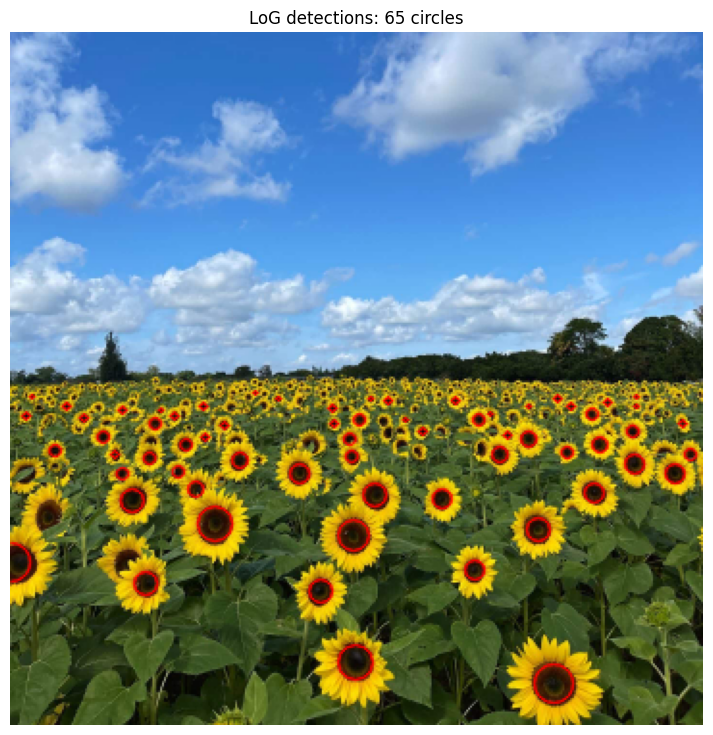


Largest detected circles
-----------------------------------------------------------------
Rank  Center (x, y)       Sigma     Radius    Response  
1     ( 282,  338)      7.22      10.21     0.3497    
2     (   0,  275)      7.22      10.21     0.3383    
3     ( 106,  255)      6.13      8.67      0.3618    
4     ( 179,  327)      6.13      8.67      0.3452    
5     ( 178,  261)      5.65      8.00      0.3527    
6     ( 161,  290)      4.43      6.26      0.3656    
7     ( 189,  240)      4.43      6.26      0.3647    
8     (  63,  243)      4.43      6.26      0.3585    
9     (  70,  286)      4.43      6.26      0.3526    
10    ( 274,  258)      4.43      6.26      0.3449    
11    ( 303,  239)      3.76      5.32      0.3869    
12    ( 241,  279)      3.76      5.32      0.3839    
13    ( 150,  229)      3.76      5.32      0.3720    
14    ( 345,  229)      3.47      4.90      0.3809    
15    ( 324,  224)      3.47      4.90      0.3711    

Sigma range used: 0.80 to

In [27]:

import cv2
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_laplace, maximum_filter

image_path = "images/the_berry_farms_sunflower_field.jpeg"
im = cv2.imread(image_path, cv2.IMREAD_REDUCED_COLOR_4)

if im is None:
    raise FileNotFoundError(f"Could not load {image_path}")

gray = cv2.cvtColor(im, cv2.COLOR_BGR2GRAY).astype(np.float32) / 255.0

sigmas = np.geomspace(0.8, 10.0, 32)

responses = np.stack([
    sigma**2 * np.abs(gaussian_laplace(gray, sigma=sigma))
    for sigma in sigmas
], axis=0)

neighborhood = (3, 5, 5)
local_max = maximum_filter(responses, size=neighborhood)

threshold = 0.003
candidates = (responses == local_max) & (responses > threshold)
indices = np.argwhere(candidates)

blobs = []
for scale_idx, y, x in indices:
    sigma = sigmas[scale_idx]
    radius = np.sqrt(2) * sigma
    score = responses[scale_idx, y, x]
    blobs.append((float(score), int(x), int(y),
                  float(sigma), float(radius)))

blobs.sort(reverse=True)

selected = []
for blob in blobs:
    score, x, y, sigma, radius = blob

    duplicate = False
    for _, bx, by, _, br in selected:
        distance = np.hypot(x - bx, y - by)

        if distance < 0.35 * min(radius, br):
            duplicate = True
            break

    if not duplicate:
        selected.append(blob)

selected = selected[:65]

output = im.copy()

for score, x, y, sigma, radius in selected:
    cv2.circle(
        output,
        (x, y),
        max(1, int(round(radius))),
        (0, 0, 255),
        1,
        cv2.LINE_AA
    )

plt.figure(figsize=(14, 9))
plt.imshow(cv2.cvtColor(output, cv2.COLOR_BGR2RGB))
plt.title(f"LoG detections: {len(selected)} circles")
plt.axis("off")
plt.show()

largest = sorted(
    selected,
    key=lambda blob: blob[4],
    reverse=True
)[:15]

print("\nLargest detected circles")
print("-" * 65)
print(f"{'Rank':<6}{'Center (x, y)':<20}{'Sigma':<10}"
      f"{'Radius':<10}{'Response':<10}")

for i, (score, x, y, sigma, radius) in enumerate(largest, start=1):
    print(
        f"{i:<6}({x:>4}, {y:>4})      "
        f"{sigma:<10.2f}{radius:<10.2f}{score:<10.4f}"
    )

print(f"\nSigma range used: {sigmas.min():.2f} to {sigmas.max():.2f} pixels")


## Question 2